# 4DEnVarOcn ACC maps in 5-year blocks with a fixed 1980–1995 climatology

Does the skill of **E3SMv3-4DEnVarOcn** (May starts 1980–1995) hold up through its record, and how does it compare with **E3SMv3-Reanalysis** in each period? All anomalies are taken against **one fixed climatology, 1980–1995**: the model drift climatology (from the prepared caches) and the observed climatology of the same verification seasons. The ACC is then evaluated separately on the 5-year blocks 1980–1984, 1985–1989 and 1990–1995, with the full 1980–1995 period as the reference column.

**Why the uncentred ACC.** The usual (Pearson) ACC subtracts each block's own mean, so the climatology would make no difference to it. Here the ACC is computed from the anomalies against the fixed climatology without re-centring,

ACC = Σ f′o′ / √(Σ f′² Σ o′²) over the start years of the block,

with f′ the ensemble-mean and o′ the observed anomaly. A block in which the model is offset from the observations (e.g. a period-dependent drift) is therefore penalised, which is the point of a fixed climatology. Over the full 1980–1995 period the anomalies have zero mean, so the last column equals the usual ACC (and the 1a maps for that period).

Every figure is drawn twice (`DETREND_OPTIONS`): with a linear trend over 1980–1995 removed from both anomalies first (one trend for the whole record, so the blocks keep a common reference; file tag `detrend`), and without detrending (`nodetrend`), where the warming trend itself contributes to the block ACC.

**Caution.** A block has only 5–6 start years: a single-point ACC needs about 0.75–0.8 to be significant at p < 0.1, so read the maps for large-scale patterns and the area-mean values in the panel labels, not for individual grid points.

Inputs are only read: the 1a prepared-anomaly caches with the 1980–1995 climatology (`*_y1980-1995_ny16_clim_1980_1995_*`) and the prepared observations, under the test diagnostic root. Run the 1980–1995 fair period of `run_fair_periods.py` (or 1a with those settings) first if a cache is missing.


In [1]:
# Test-run output roots (set before importing esp_lab so every module sees them).
import os
os.environ["ESP_LAB_FIGURE_ROOT"] = "/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures"
os.environ["ESP_LAB_S2D_DIAG_ROOT"] = "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test"
os.environ["ESP_LAB_FIGURE_GALLERY"] = "0"  # test runs: figures only, no figures.json/index.html

%matplotlib inline
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from esp_lab import env_paths
from esp_lab import sample_size_skill as sss
from esp_lab.leadtime_plot_utils import add_lead_badge, style_global_map_axis
from esp_lab.utils import mapplot_utils as maps
from esp_lab.utils.filename_utils import figure_filename
from workflows.diagnostics.sample_size import lead_labels

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


In [2]:
# =============================================================================
# CONFIGURATION BLOCK: Edit settings here
# =============================================================================
INIT_MONTH = 5
CLIMATOLOGY_YEARS = (1980, 1995)          # fixed climatology for every block
BLOCKS = [(1980, 1984), (1985, 1989), (1990, 1995)]
SHOW_FULL_PERIOD = True                   # add the full climatology period as a reference column
DETREND_OPTIONS = [True, False]           # True: remove one linear trend over CLIMATOLOGY_YEARS first

FIELDS = ["TS", "TREFHT", "PRECT", "PSL"]
PLOT_LEADS = ["JJA0", "DJF1", "JJA1"]     # one figure per field and lead (labels: season + years after start)

# Experiment, control and the difference row (experiment minus control).
EXPERIMENT = dict(tag="4DEnVarOcn", label="E3SMv3-4DEnVarOcn")
CONTROL = dict(tag="Reanalysis", label="E3SMv3-Reanalysis")
OBS_NAME = {"TS": "ERA5", "TREFHT": "ERA5", "PRECT": "GPCP v2.3", "PSL": "ERA5"}

ACC_LEVELS = (-1.0, 1.0, 0.1)             # (min, max, interval) of the ACC colour scale
DIFF_LEVELS = (-0.8, 0.8, 0.1)            # same for the difference row
AREA_LATLIM = 80                          # |lat| limit of the area-mean ACC in the panel labels
FIGURE_SET = "4DEnVarOcn_5yr_blocks"      # figures go to <figure root>/<FIGURE_SET>/
# ===== END CONFIGURATION BLOCK =====

DIAG_ROOT = env_paths.s2d_diag_root()
FIGURE_DIR = env_paths.figure_root() / FIGURE_SET
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
y0, y1 = CLIMATOLOGY_YEARS
print(f"Diagnostics: {DIAG_ROOT}\nFigures: {FIGURE_DIR}")

Diagnostics: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test
Figures: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks


## Inputs

Model anomalies come from the prepared caches (already relative to the 1980–1995 drift climatology); observed anomalies are the prepared observations at each verification season minus their 1980–1995 mean.

In [3]:
def prepared_path(tag, field):
    folder = DIAG_ROOT / tag / "leadtime_acc" / "prepared_skill" / "atm" / field
    name = (f"{tag}_init{INIT_MONTH:02d}_{field}_seasonal_anomaly_y{y0}-{y1}_ny{y1 - y0 + 1}"
            f"_clim_{y0}_{y1}_m*_l*_5x5deg_skill_v1.nc")
    found = sorted(folder.glob(name))
    if len(found) != 1:
        raise FileNotFoundError(f"expected one prepared cache {folder / name}, found {len(found)}")
    return found[0]


def observed_anomaly(field, valid_time):
    """Observed seasonal anomalies (Y, L, lat, lon) against the same-years climatology."""
    folder = DIAG_ROOT / "observations" / "leadtime_acc" / "prepared_skill" / "atm" / field
    obs = xr.open_dataset(sorted(folder.glob(f"*_{field}_seasonal_5x5deg_skill_v1.nc"))[0])["observation"]
    at = sss.observations_at_valid_time(obs, valid_time)
    return at - at.mean("Y")


def detrend(anom):
    """Remove one least-squares linear trend in start year (per lead and grid cell)."""
    t = xr.DataArray(sss.init_years(anom.Y.values).astype(float), dims="Y", coords={"Y": anom.Y})
    t = t - t.mean()
    slope = (anom * t).sum("Y") / (t ** 2).sum()
    return anom - anom.mean("Y") - slope * t


def load_field(field, detrend_anomalies):
    """{label: ensemble-mean anomaly} for experiment and control, plus the observed anomaly."""
    data, valid_time = {}, None
    for case in (EXPERIMENT, CONTROL):
        ds = xr.open_dataset(prepared_path(case["tag"], field))
        if (int(ds.attrs["climatology_start_year"]), int(ds.attrs["climatology_end_year"])) != CLIMATOLOGY_YEARS:
            raise ValueError(f"{case['tag']} {field}: cache climatology is not {CLIMATOLOGY_YEARS}")
        data[case["label"]] = ds["anomaly"].mean("M").load()
        valid_time = ds["time"] if valid_time is None else valid_time
    obs = observed_anomaly(field, valid_time)
    labels = lead_labels(valid_time)
    if detrend_anomalies:
        data = {k: detrend(v) for k, v in data.items()}
        obs = detrend(obs)
    return data, obs, labels


def uncentred_acc(fcst, obs, years):
    """ACC from anomalies against the fixed climatology over the start years ``years``."""
    sel = np.isin(sss.init_years(fcst.Y.values), np.arange(years[0], years[1] + 1))
    f, o = fcst.isel(Y=sel), obs.isel(Y=sel)
    complete = (f.notnull() & o.notnull()).all("Y")
    acc = (f * o).sum("Y") / np.sqrt((f ** 2).sum("Y") * (o ** 2).sum("Y"))
    return acc.where(complete & np.isfinite(acc))


def area_mean(acc):
    w = np.cos(np.deg2rad(acc.lat)).where(abs(acc.lat) < AREA_LATLIM)
    return float(acc.weighted(w.fillna(0)).mean(("lat", "lon")))

## Block ACC

For every field: the uncentred ACC of the experiment and the control in each block (and over the full period), and their difference. The table lists the area-mean ACC (cos-latitude weighted, |lat| < 80°) per block.

In [4]:
COLUMNS = list(BLOCKS) + ([CLIMATOLOGY_YEARS] if SHOW_FULL_PERIOD else [])
results, rows = {}, []
for detrended in DETREND_OPTIONS:
    for field in FIELDS:
        data, obs, labels = load_field(field, detrended)
        acc = {(label, years): uncentred_acc(fcst, obs, years) for label, fcst in data.items() for years in COLUMNS}
        results[(field, detrended)] = dict(acc=acc, labels=labels)
        for (label, years), a in acc.items():
            for lead, name in zip(a.L.values, labels):
                rows.append(dict(field=field, detrend=detrended, experiment=label, years=f"{years[0]}-{years[1]}",
                                 lead=name, area_mean_acc=area_mean(a.sel(L=lead))))
        print(f"done: {field} ({'detrended' if detrended else 'not detrended'})")
summary = pd.DataFrame(rows)
summary.to_csv(FIGURE_DIR / f"acc_5yr_blocks_{EXPERIMENT['tag']}_vs_{CONTROL['tag']}_clim{y0}-{y1}.csv", index=False)
(summary[summary.lead.isin(PLOT_LEADS)]
 .pivot_table(index=["detrend", "field", "lead", "experiment"], columns="years", values="area_mean_acc", sort=False).round(2))

done: TS (detrended)


done: TREFHT (detrended)


done: PRECT (detrended)


done: PSL (detrended)


done: TS (not detrended)


done: TREFHT (not detrended)


done: PRECT (not detrended)


done: PSL (not detrended)


years                                  1980-1984  1985-1989  1990-1995  \
detrend field  lead experiment                                           
True    TS     JJA0 E3SMv3-4DEnVarOcn       0.20       0.25       0.07   
                    E3SMv3-Reanalysis       0.40       0.41       0.43   
               DJF1 E3SMv3-4DEnVarOcn       0.25       0.17       0.05   
                    E3SMv3-Reanalysis       0.13       0.22       0.13   
               JJA1 E3SMv3-4DEnVarOcn       0.19       0.07       0.03   
                    E3SMv3-Reanalysis       0.13       0.11       0.16   
        TREFHT JJA0 E3SMv3-4DEnVarOcn       0.20       0.27       0.07   
                    E3SMv3-Reanalysis       0.38       0.39       0.36   
               DJF1 E3SMv3-4DEnVarOcn       0.28       0.20       0.05   
                    E3SMv3-Reanalysis       0.11       0.21       0.11   
               JJA1 E3SMv3-4DEnVarOcn       0.20       0.07       0.05   
                    E3SMv3-Reanalysis       0.16       0.09       0.16   
        PRECT  JJA0 E3SMv3-4DEnVarOcn       0.17       0.14       0.05   
                    E3SMv3-Reanalysis       0.19       0.17       0.16   
               DJF1 E3SMv3-4DEnVarOcn       0.15       0.07       0.04   
                    E3SMv3-Reanalysis       0.10       0.02       0.08   
               JJA1 E3SMv3-4DEnVarOcn       0.08       0.01      -0.01   
                    E3SMv3-Reanalysis       0.06       0.00       0.05   
        PSL    JJA0 E3SMv3-4DEnVarOcn       0.34       0.22       0.03   
                    E3SMv3-Reanalysis       0.33       0.29       0.34   
               DJF1 E3SMv3-4DEnVarOcn       0.47       0.22      -0.01   
                    E3SMv3-Reanalysis       0.20       0.12       0.21   
               JJA1 E3SMv3-4DEnVarOcn       0.21      -0.10      -0.01   
                    E3SMv3-Reanalysis       0.09       0.19      -0.03   
False   TS     JJA0 E3SMv3-4DEnVarOcn       0.20       0.25       0.12   
                    E3SMv3-Reanalysis       0.39       0.41       0.43   
               DJF1 E3SMv3-4DEnVarOcn       0.25       0.16       0.07   
                    E3SMv3-Reanalysis       0.16       0.22       0.16   
               JJA1 E3SMv3-4DEnVarOcn       0.21       0.07       0.07   
                    E3SMv3-Reanalysis       0.16       0.12       0.16   
        TREFHT JJA0 E3SMv3-4DEnVarOcn       0.19       0.28       0.13   
                    E3SMv3-Reanalysis       0.36       0.40       0.38   
               DJF1 E3SMv3-4DEnVarOcn       0.27       0.20       0.08   
                    E3SMv3-Reanalysis       0.12       0.21       0.16   
               JJA1 E3SMv3-4DEnVarOcn       0.23       0.07       0.10   
                    E3SMv3-Reanalysis       0.16       0.11       0.16   
        PRECT  JJA0 E3SMv3-4DEnVarOcn       0.15       0.15       0.07   
                    E3SMv3-Reanalysis       0.16       0.17       0.15   
               DJF1 E3SMv3-4DEnVarOcn       0.13       0.07       0.04   
                    E3SMv3-Reanalysis       0.10       0.02       0.08   
               JJA1 E3SMv3-4DEnVarOcn       0.07       0.01       0.01   
                    E3SMv3-Reanalysis       0.07       0.00       0.07   
        PSL    JJA0 E3SMv3-4DEnVarOcn       0.29       0.21       0.05   
                    E3SMv3-Reanalysis       0.30       0.28       0.30   
               DJF1 E3SMv3-4DEnVarOcn       0.48       0.20       0.02   
                    E3SMv3-Reanalysis       0.20       0.13       0.24   
               JJA1 E3SMv3-4DEnVarOcn       0.20      -0.10       0.01   
                    E3SMv3-Reanalysis       0.10       0.19       0.03   

years                                  1980-1995  
detrend field  lead experiment                    
True    TS     JJA0 E3SMv3-4DEnVarOcn       0.19  
                    E3SMv3-Reanalysis       0.44  
               DJF1 E3SMv3-4DEnVarOcn       0.16  
                    E3SMv3-Reanalysis       

## Maps

Rows: experiment, control, experiment minus control. Columns: the 5-year blocks and the full period. Each panel label gives the area-mean ACC (or ACC difference).

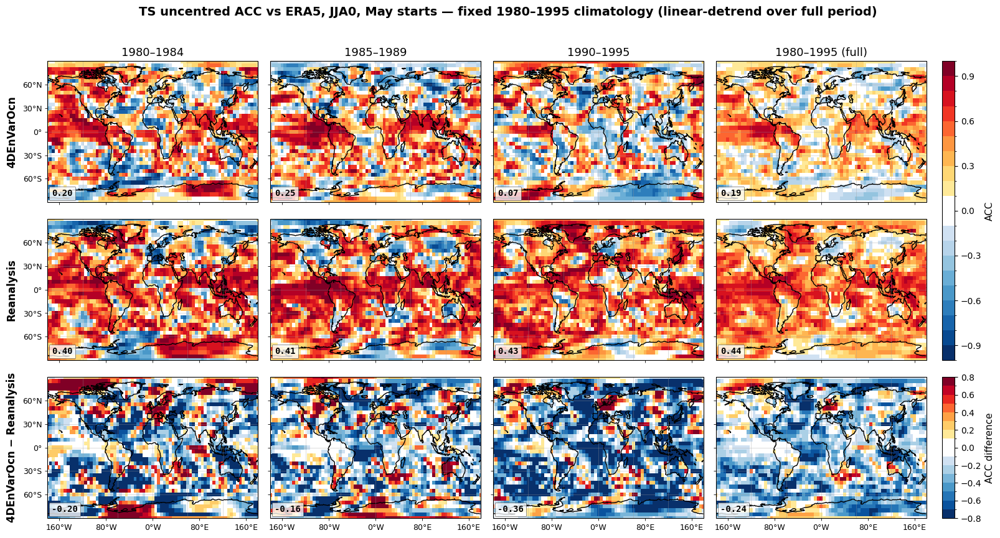

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_jja0_clim1980_1995_detrend.png


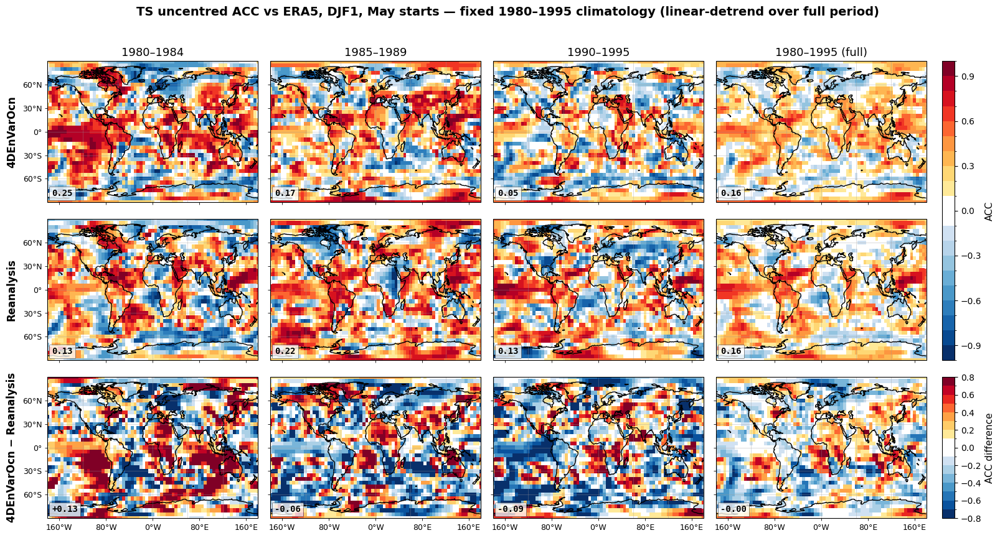

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_djf1_clim1980_1995_detrend.png


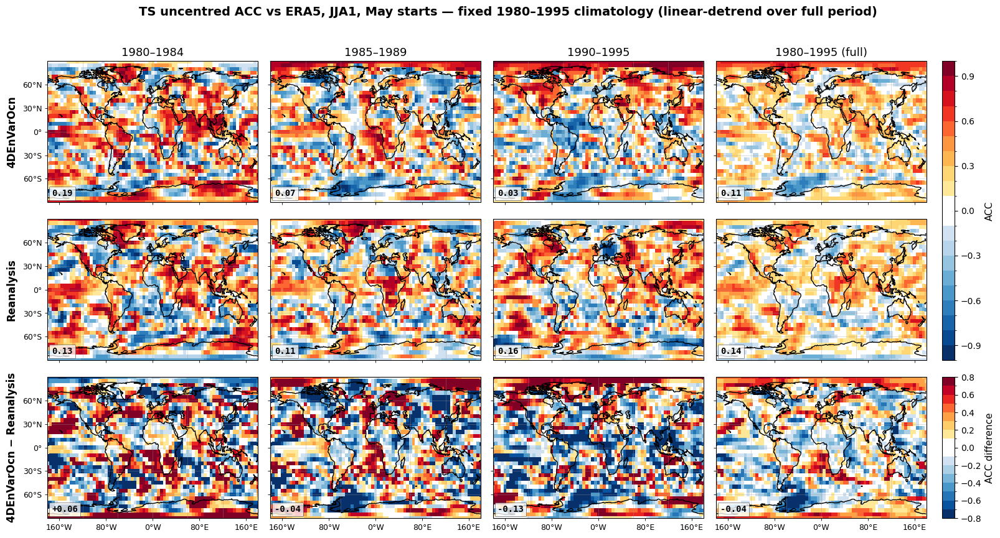

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_jja1_clim1980_1995_detrend.png


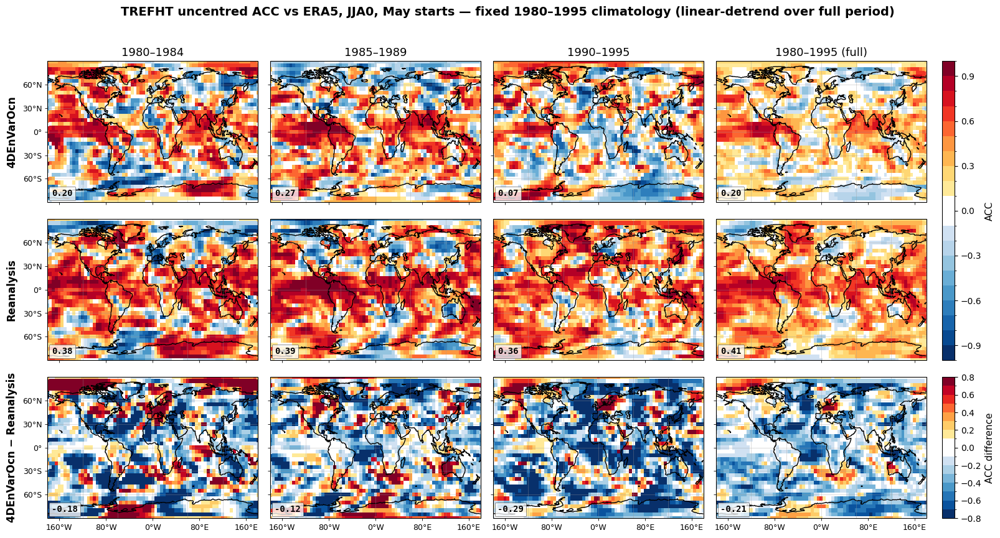

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_jja0_clim1980_1995_detrend.png


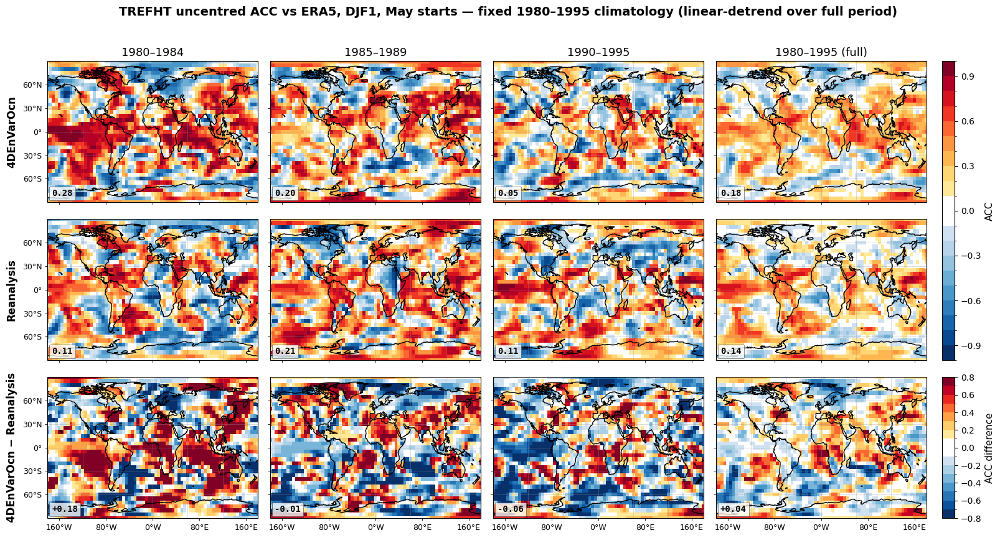

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_djf1_clim1980_1995_detrend.png


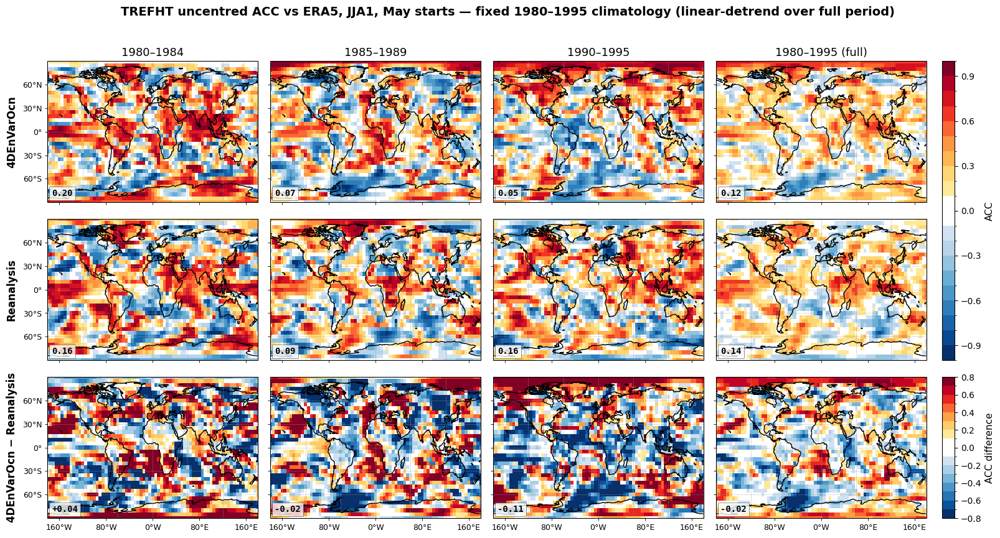

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_jja1_clim1980_1995_detrend.png


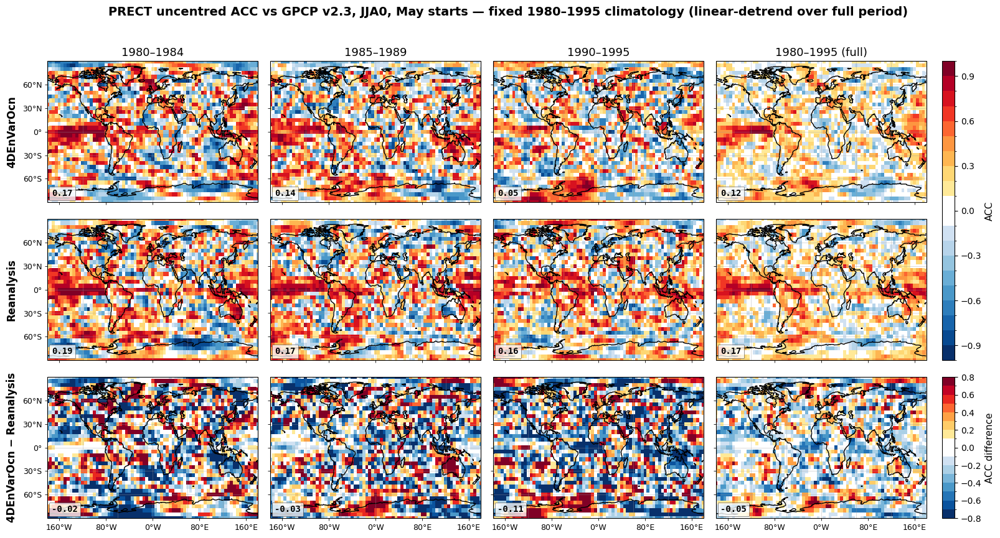

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_jja0_clim1980_1995_detrend.png


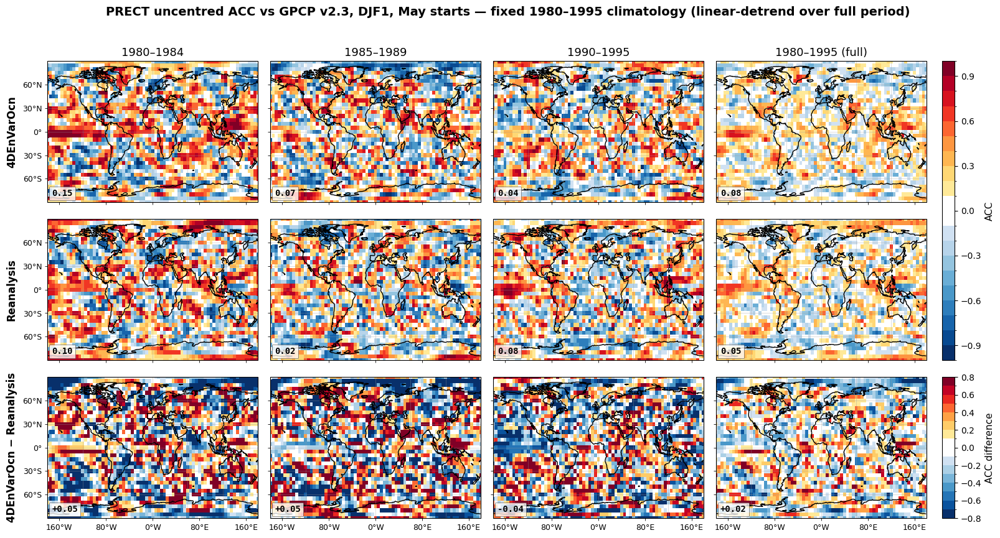

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_djf1_clim1980_1995_detrend.png


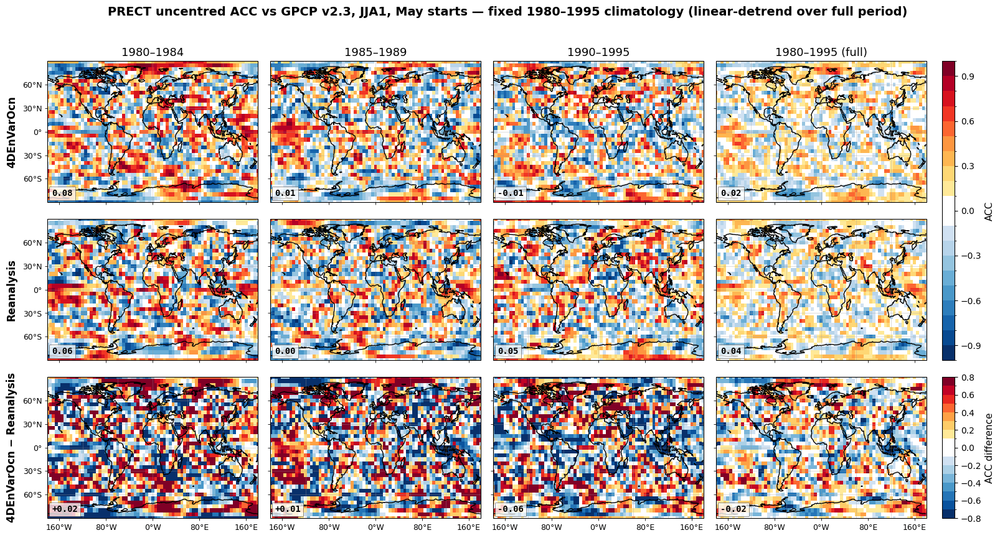

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_jja1_clim1980_1995_detrend.png


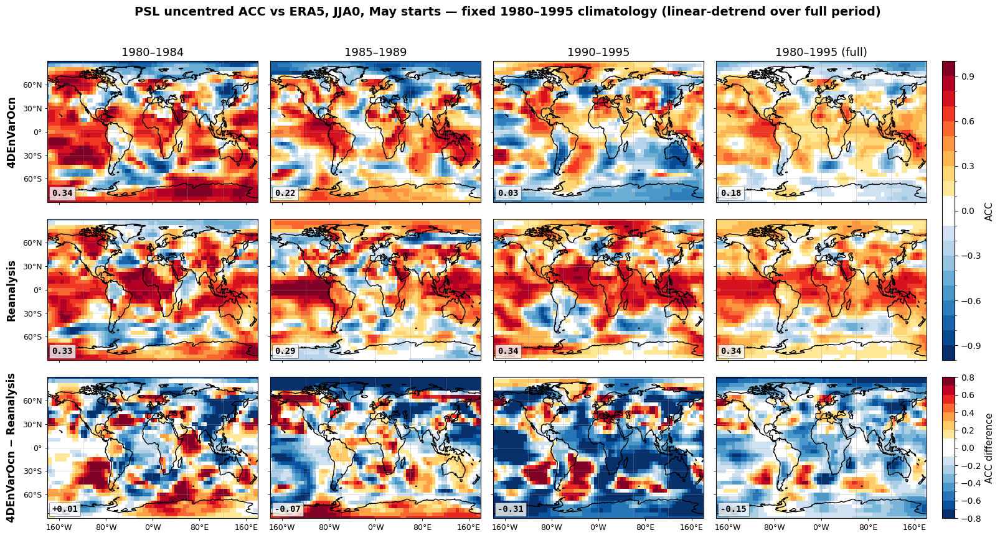

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_jja0_clim1980_1995_detrend.png


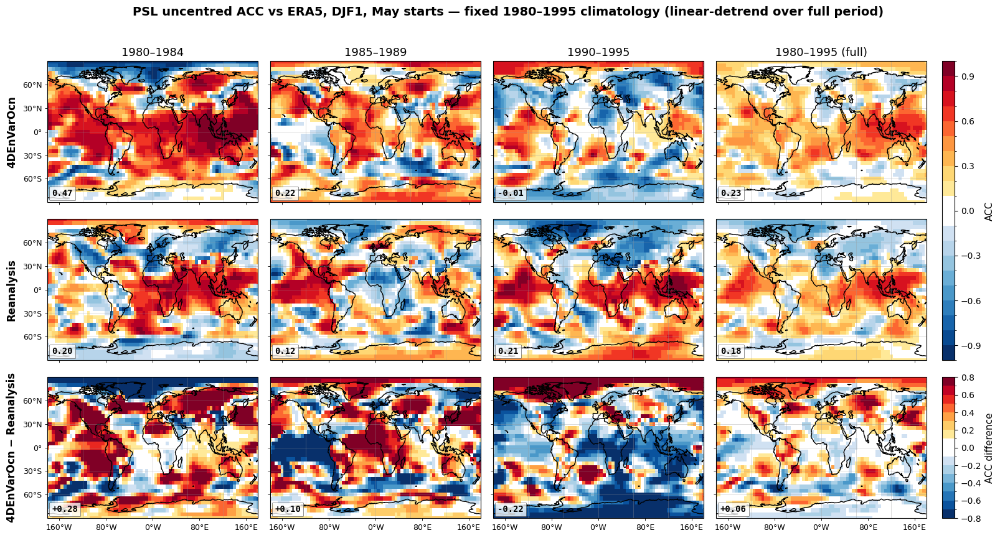

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_djf1_clim1980_1995_detrend.png


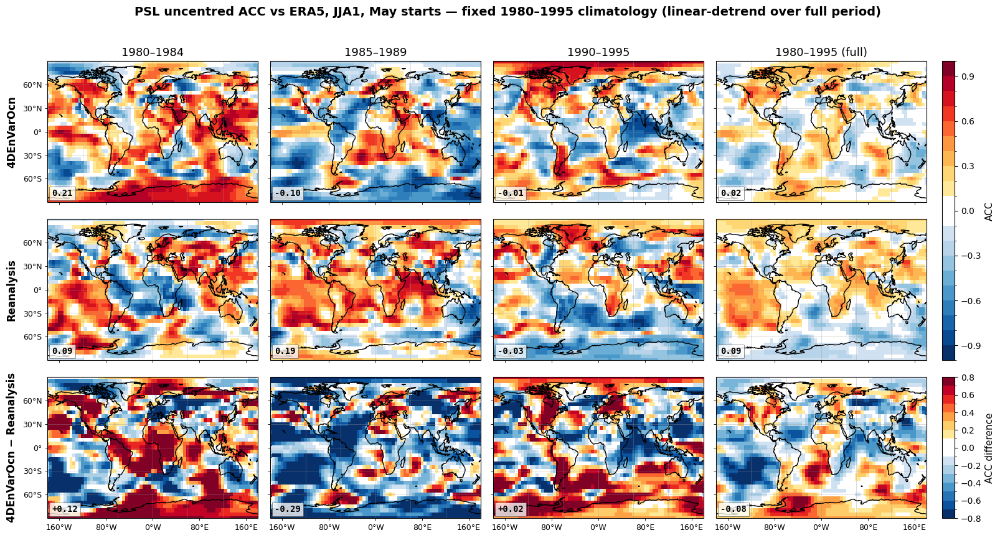

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_jja1_clim1980_1995_detrend.png


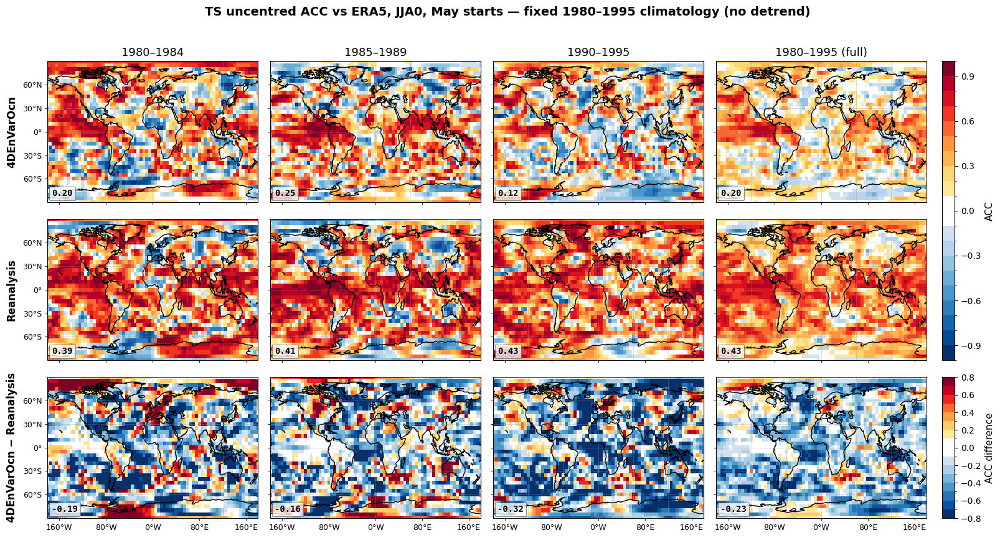

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_jja0_clim1980_1995_nodetrend.png


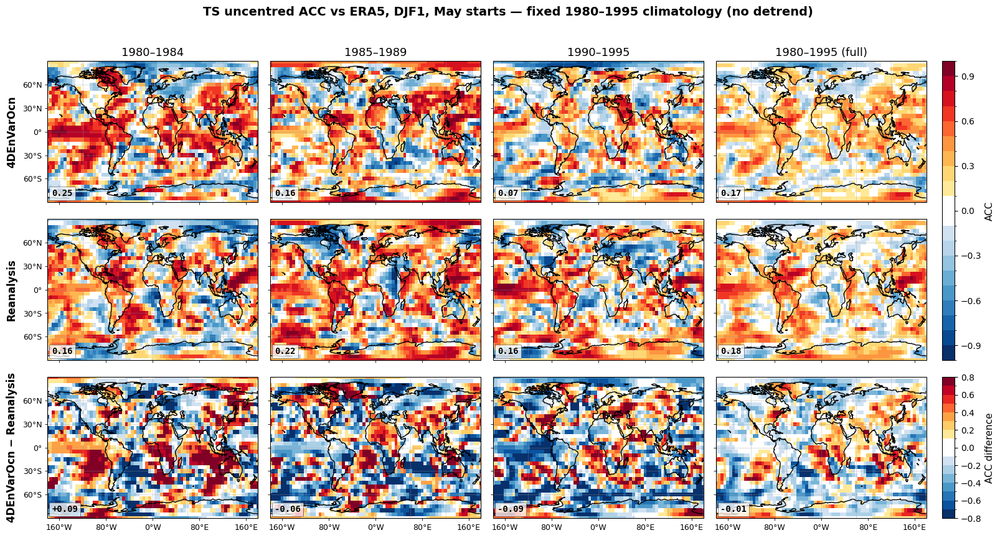

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_djf1_clim1980_1995_nodetrend.png


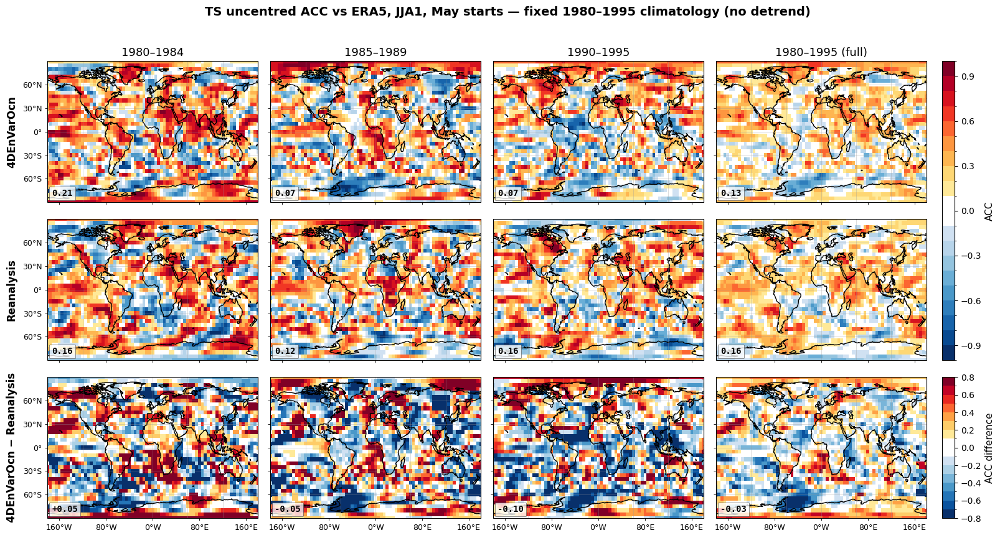

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_jja1_clim1980_1995_nodetrend.png


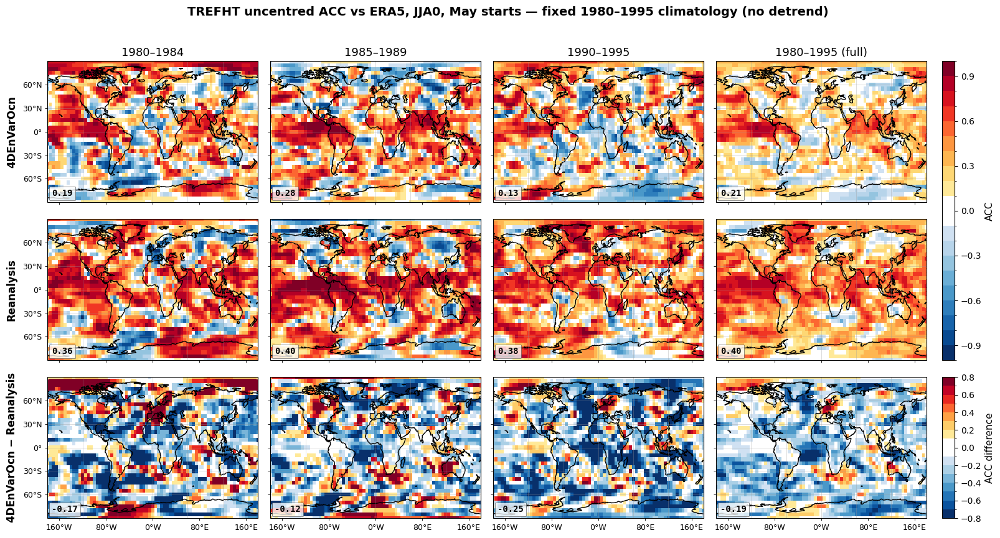

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_jja0_clim1980_1995_nodetrend.png


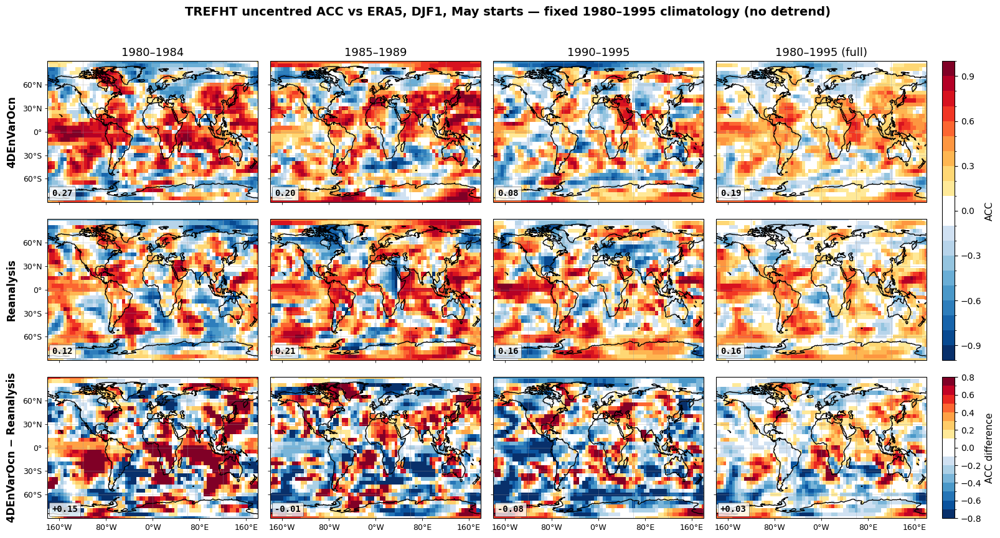

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_djf1_clim1980_1995_nodetrend.png


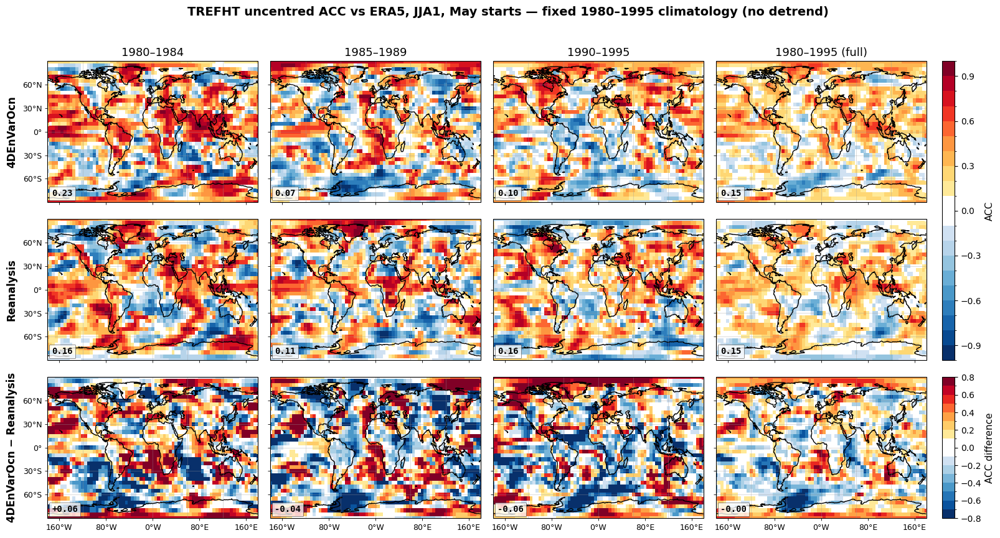

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_jja1_clim1980_1995_nodetrend.png


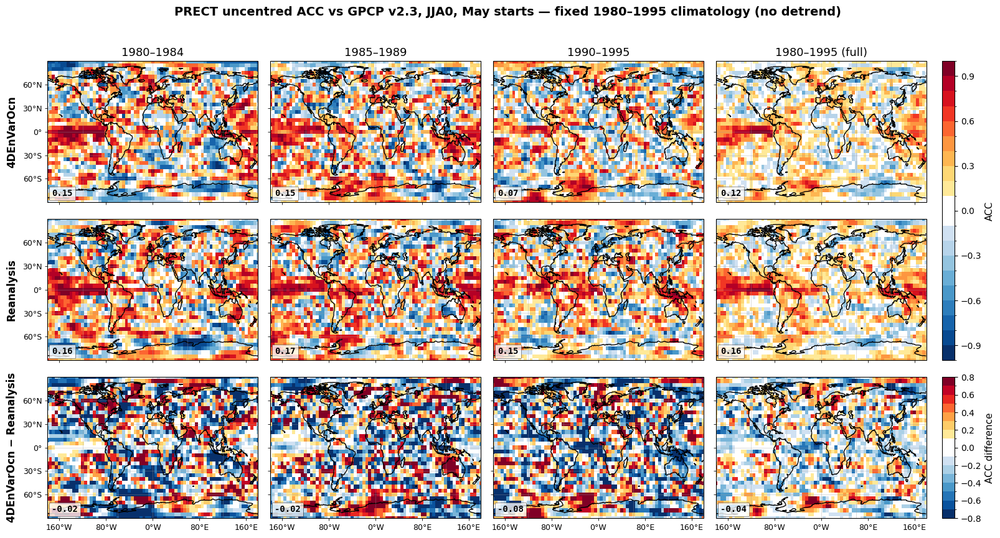

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_jja0_clim1980_1995_nodetrend.png


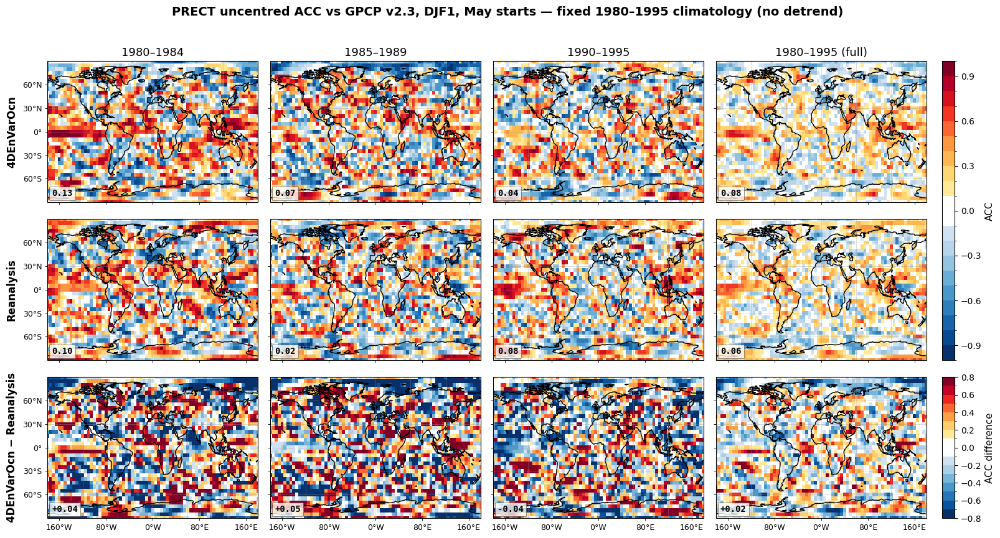

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_djf1_clim1980_1995_nodetrend.png


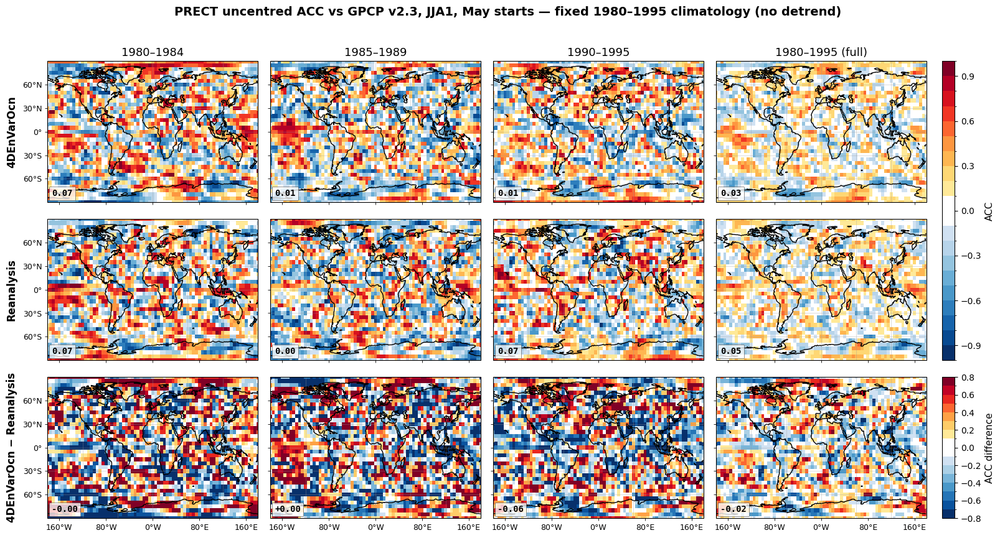

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_jja1_clim1980_1995_nodetrend.png


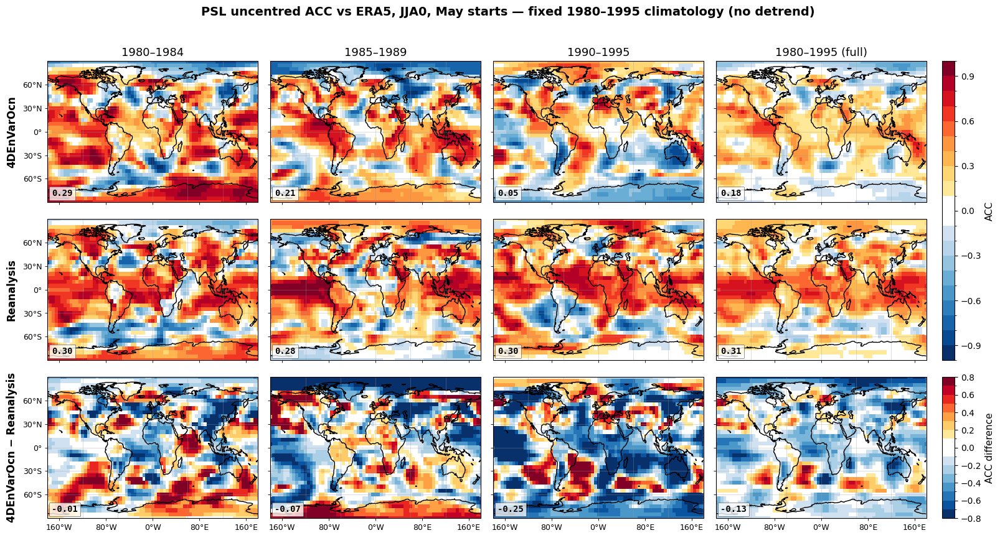

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_jja0_clim1980_1995_nodetrend.png


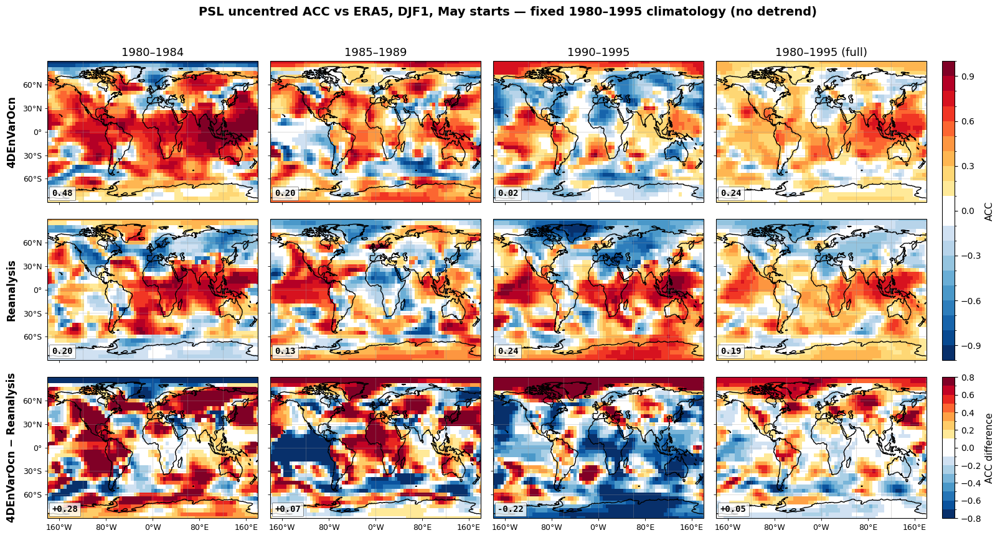

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_djf1_clim1980_1995_nodetrend.png


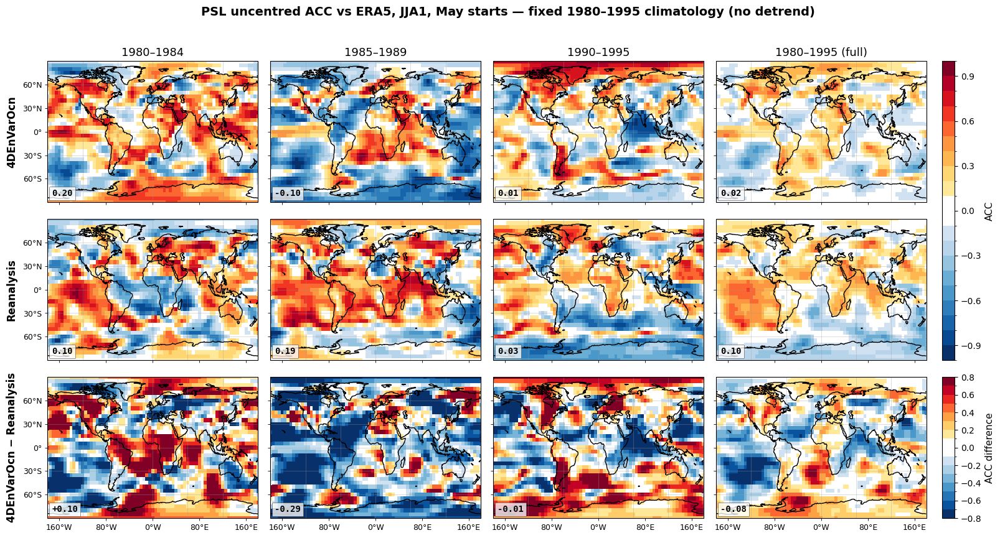

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_jja1_clim1980_1995_nodetrend.png


In [5]:
PROJECTION = ccrs.PlateCarree()
MAP_STYLE = dict(lon_ticks=[-160, -80, 0, 80, 160], lat_ticks=[-60, -30, 0, 30, 60],
                 tick_length=3, tick_width=0.6, grid_linewidth=0.4, grid_color="0.6", grid_alpha=0.6)


def plot_blocks(field, lead_name, detrended):
    res = results[(field, detrended)]
    lead = res["acc"][(EXPERIMENT["label"], COLUMNS[0])].L.values[res["labels"].index(lead_name)]
    row_specs = [(EXPERIMENT["label"], "acc"), (CONTROL["label"], "acc"),
                 (f"{EXPERIMENT['label']} − {CONTROL['label'].replace('E3SMv3-', '')}", "diff")]
    nrows, ncols = len(row_specs), len(COLUMNS)
    fig = plt.figure(figsize=(4.2 * ncols, 2.55 * nrows + 1.2))
    mappables = {}
    for r, (row_label, kind) in enumerate(row_specs):
        for c, years in enumerate(COLUMNS):
            exp = res["acc"][(EXPERIMENT["label"], years)].sel(L=lead)
            ctl = res["acc"][(CONTROL["label"], years)].sel(L=lead)
            panel = {0: exp, 1: ctl, 2: exp - ctl}[r]
            vmin, vmax, step = ACC_LEVELS if kind == "acc" else DIFF_LEVELS
            title = (f"{years[0]}–{years[1]}" + (" (full)" if years == CLIMATOLOGY_YEARS else "")) if r == 0 else ""
            ax, mappables[kind] = maps.map_pcolor_global_subplot(
                fig, panel, panel.lon, panel.lat, step, vmin, vmax, title, nrows, ncols,
                r * ncols + c + 1, PROJECTION, fontsize=13)
            style_global_map_axis(ax, row=r, column=c, nrows=nrows, label_size=9, style=MAP_STYLE)
            sign = "+" if kind == "diff" else ""
            add_lead_badge(ax, f"{area_mean(panel):{sign}.2f}", font_size=10, location="lower left")
            if c == 0:
                ax.text(-0.17, 0.5, row_label.replace("E3SMv3-", ""), transform=ax.transAxes, rotation=90,
                        ha="center", va="center", fontsize=12, fontweight="bold")
    fig.subplots_adjust(left=0.06, right=0.9, top=0.88, bottom=0.05, wspace=0.06, hspace=0.12)
    for kind, label, rows_ in (("acc", "ACC", (0, 1)), ("diff", "ACC difference", (2,))):
        top = fig.axes[rows_[0] * ncols].get_position().y1
        bottom = fig.axes[rows_[-1] * ncols].get_position().y0
        cax = fig.add_axes([0.915, bottom, 0.012, top - bottom])
        fig.colorbar(mappables[kind], cax=cax).set_label(label, fontsize=11)
    trend = "linear-detrend over full period" if detrended else "no detrend"
    fig.suptitle(f"{field} uncentred ACC vs {OBS_NAME.get(field, 'obs')}, {lead_name}, May starts — "
                 f"fixed {y0}–{y1} climatology ({trend})", fontsize=14, fontweight="bold")
    path = FIGURE_DIR / figure_filename("acc_5yr_blocks", EXPERIMENT["tag"], "vs", CONTROL["tag"], field,
                                        f"init{INIT_MONTH:02d}", lead_name, f"clim{y0}-{y1}",
                                        "detrend" if detrended else "nodetrend")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return path


for detrended in DETREND_OPTIONS:
    for field in FIELDS:
        for lead_name in PLOT_LEADS:
            print(plot_blocks(field, lead_name, detrended))